In [7]:
#Importation 
import math
import numpy as np
import numpy as np
from math import sin, cos, atan2
import matplotlib.pyplot as plt

In [8]:
#Global variable 
ROT_SPEED_TO_M_PER_S = 0.0003375  # needs to be calibrated
WHEEL_BASE = 0.095 # needs to be calibrated

In [9]:
def wrap_to_pi(a):
    return atan2(sin(a), cos(a))

In [10]:
def odometry(rot_speed_left_motor, rot_speed_right_motor, X_position, Y_position, angle_position_rad, delta_time):
    
    #Linear speed
    linear_speed_left = rot_speed_left_motor * ROT_SPEED_TO_M_PER_S
    linear_speed_right = rot_speed_right_motor * ROT_SPEED_TO_M_PER_S
    linear_speed = (linear_speed_right + linear_speed_left) / 2 
    
    #Angular speed
    angular_speed = (linear_speed_right - linear_speed_left) / WHEEL_BASE  # rad/s

    angle_mid = angle_position_rad + angular_speed * delta_time / 2 #middle point to make an etimation of 2 segment
     
    X_new = X_position + linear_speed * math.cos(angle_mid) * delta_time
    Y_new = Y_position + linear_speed * math.sin(angle_mid) * delta_time
    angle_new = angle_position_rad + angular_speed * delta_time

    return X_new, Y_new, angle_new

In [11]:
# constants, to tune
SIGMA_D2 = 1e-4      # variance added per meter driven
SIGMA_TH2 = 1e-3     # variance added per radian turned
Q_MIN = 1e-8         # small floor so P never becomes exactly 0
R = np.diag([1e-4, 1e-4, 1e-3])   # camera uncertainty
H = np.eye(3)

# initialization from the first camera frame: only for the real robot
# state = np.array(CV())
# P = R.copy()

In [12]:
def kalman(state, P, speed_left, speed_right, dt, camera_pose):

    # ---------- PREDICTION ----------
    X, Y, theta = state
    state_pred = np.array(odometry(speed_left, speed_right, X, Y, theta, dt))
    state_pred[2] = wrap_to_pi(state_pred[2])

    v = (speed_right + speed_left) * ROT_SPEED_TO_M_PER_S / 2
    omega = (speed_right - speed_left) * ROT_SPEED_TO_M_PER_S / WHEEL_BASE
    theta_mid = theta + omega * dt / 2

    # F: how an error in the previous state propagates into the new state
    F = np.array([[1, 0, -v * sin(theta_mid) * dt],
                  [0, 1,  v * cos(theta_mid) * dt],
                  [0, 0,  1]])

    # Q: uncertainty added by this step, proportional to the motion
    q_xy = SIGMA_D2 * abs(v * dt) + Q_MIN
    q_th = SIGMA_TH2 * abs(omega * dt) + Q_MIN
    Q = np.diag([q_xy, q_xy, q_th])

    P_pred = F @ P @ F.T + Q

    if camera_pose is None:
        return state_pred, P_pred          # odometry only

    # ---------- UPDATE ----------
    innovation = camera_pose - H @ state_pred
    innovation[2] = wrap_to_pi(innovation[2])

    S = H @ P_pred @ H.T + R
    K = P_pred @ H.T @ np.linalg.inv(S)

    state_new = state_pred + K @ innovation
    state_new[2] = wrap_to_pi(state_new[2])
    P_new = (np.eye(3) - K @ H) @ P_pred
    return state_new, P_new

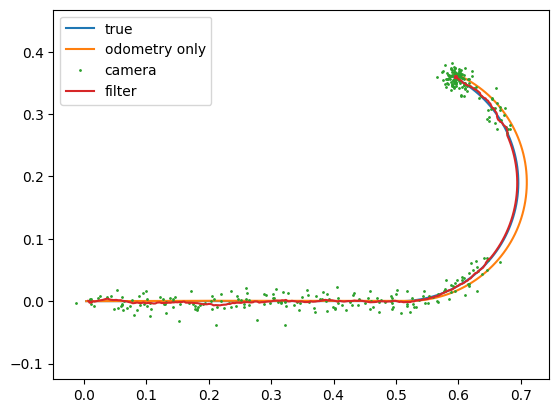

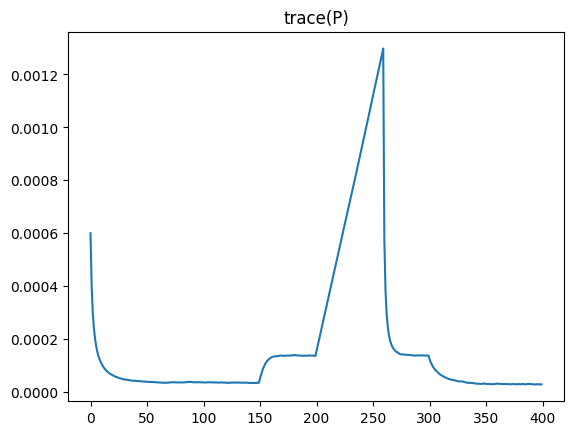

mean position error, filter: 0.0028857527967838348
mean position error, odometry: 0.010093273309792173


In [13]:
#Test : 
rng = np.random.default_rng(0)
dt = 0.05
n_steps = 400

true_pose = np.array([0.0, 0.0, 0.0])
state = true_pose.copy()
P = R.copy()
odo_only = true_pose.copy()

true_hist, est_hist, odo_hist, cam_hist, trace_hist = [], [], [], [], []

for k in range(n_steps):
    # true commanded speeds: drive, then curve, then stop
    if k < 150:
        sl, sr = 200, 200
    elif k < 300:
        sl, sr = 150, 250
    else:
        sl, sr = 0, 0

    # true motion (what the robot really does)
    X, Y, th = odometry(sl, sr, *true_pose, dt)
    true_pose = np.array([X, Y, th])

    # measured wheel speeds are slightly wrong (calibration error + noise)
    sl_meas = sl * 1.03 + rng.normal(0, 3)
    sr_meas = sr * 1.03 + rng.normal(0, 3)

    # fake camera: noisy true pose, lost between steps 200 and 260
    if 200 <= k < 260:
        cam = None
    else:
        cam = true_pose + rng.normal(0, np.sqrt(np.diag(R)))

    # odometry alone, for comparison
    odo_only = np.array(odometry(sl_meas, sr_meas, *odo_only, dt))

    # filter
    state, P = kalman(state, P, sl_meas, sr_meas, dt, cam)

    true_hist.append(true_pose.copy())
    est_hist.append(state.copy())
    odo_hist.append(odo_only.copy())
    cam_hist.append(cam if cam is not None else [np.nan]*3)
    trace_hist.append(np.trace(P))

#Plotting : 

import matplotlib.pyplot as plt

true_a, est_a = np.array(true_hist), np.array(est_hist)
odo_a, cam_a = np.array(odo_hist), np.array(cam_hist)

plt.figure()
plt.plot(true_a[:,0], true_a[:,1], label="true")
plt.plot(odo_a[:,0], odo_a[:,1], label="odometry only")
plt.plot(cam_a[:,0], cam_a[:,1], ".", ms=2, label="camera")
plt.plot(est_a[:,0], est_a[:,1], label="filter")
plt.axis("equal"); plt.legend()

plt.figure()
plt.plot(trace_hist); plt.title("trace(P)")
plt.show()

err = lambda a: np.linalg.norm(a[:,:2] - true_a[:,:2], axis=1).mean()
print("mean position error, filter:", err(est_a))
print("mean position error, odometry:", err(odo_a))


x, y, th = 0, 0, 0
for _ in range(100):
    x, y, th = odometry(200, 200, x, y, th, 0.05)
assert abs(y) < 1e-9 and abs(th) < 1e-9 and x > 0